### *Import Libraries*



In [55]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)
import matplotlib

import matplotlib.pyplot as plt
import seaborn as sns

In [56]:
%matplotlib inline

In [57]:
RANDOM_STATE = 42

### Load Data

In [58]:
red = pd.read_csv("winequality-red.csv", sep=";")
white = pd.read_csv("winequality-white.csv", sep=";")

In [59]:
red["wine_type"] = 0   # red = 0
white["wine_type"] = 1  # white = 1
df = pd.concat([red, white], axis=0, ignore_index=True)
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)
print(df.head())

(5320, 13)
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.66         0.00             1.8      0.075   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 13.0                  40.0   0.9978  3.51       0.56   

   alcohol  quality  wine_type  
0      9.4        5          0  
1      9.

In [60]:

print("Combined dataset shape:", df.shape)
print(df["quality"].value_counts().sort_index())


Combined dataset shape: (5320, 13)
quality
3      30
4     206
5    1752
6    2323
7     856
8     148
9       5
Name: count, dtype: int64


In [61]:
# 2. Create binary classification target
#    "good" wine = quality >= 7, "not good" = quality < 7

df["good_quality"] = (df["quality"] >= 7).astype(int)
print("\nClass balance (good_quality):")
print(df["good_quality"].value_counts(normalize=True))

X = df.drop(columns=["quality", "good_quality"])
y = df["good_quality"]


Class balance (good_quality):
good_quality
0    0.810338
1    0.189662
Name: proportion, dtype: float64


In [62]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

# Scale features (needed for Logistic Regression; harmless for trees)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [63]:
# 3. Train models
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=12, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
}

class_weight="balanced" — tells the model to pay extra attention to the rare "good" class instead of ignoring it (important since only ~19% of wines are good).
max_depth — caps how many questions a tree can ask, so it doesn't memorize the training data (overfit).
n_estimators=300 — Random Forest builds 300 trees and averages their votes.
random_state=42 — makes results reproducible every time you rerun the code.
n_jobs=-1 — uses all your CPU cores to train faster.

In [64]:
results = []      # will hold one dict of scores per model, e.g. {"Model": "Random Forest", "Accuracy": 0.84, ...}
roc_data = {}      # will hold each model's ROC curve data, keyed by model name
fitted = {}        # will hold the actual trained model objects, keyed by model name

In [65]:
for name, model in models.items():
    if name == "Logistic Regression":
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        y_proba = model.predict_proba(X_test_scaled)[:, 1]
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_proba = model.predict_proba(X_test)[:, 1]

    fitted[name] = model

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)
    cm = confusion_matrix(y_test, y_pred)

    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_data[name] = (fpr, tpr, auc)


In [66]:
results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-score": f1,
        "ROC-AUC": auc,
    })

In [67]:
print(f"\n===== {name} =====")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {auc:.4f}")
print("Confusion Matrix:\n", cm)
print(classification_report(y_test, y_pred, target_names=["not good", "good"]))


===== Random Forest =====
Accuracy : 0.8233
Precision: 0.5250
Recall   : 0.7277
F1-score : 0.6100
ROC-AUC  : 0.8735
Confusion Matrix:
 [[729 133]
 [ 55 147]]
              precision    recall  f1-score   support

    not good       0.93      0.85      0.89       862
        good       0.53      0.73      0.61       202

    accuracy                           0.82      1064
   macro avg       0.73      0.79      0.75      1064
weighted avg       0.85      0.82      0.83      1064



In [68]:
results_df = pd.DataFrame(results).set_index("Model").round(4)
print("\n\n===== SUMMARY TABLE =====")
print(results_df)
results_df.to_csv("model_comparison_results.csv")



===== SUMMARY TABLE =====
               Accuracy  Precision  Recall  F1-score  ROC-AUC
Model                                                        
Random Forest    0.8233      0.525  0.7277      0.61   0.8735


In [69]:
# 4. Plots: metric comparison bar chart, ROC curves, confusion matrices

sns.set_style("whitegrid")

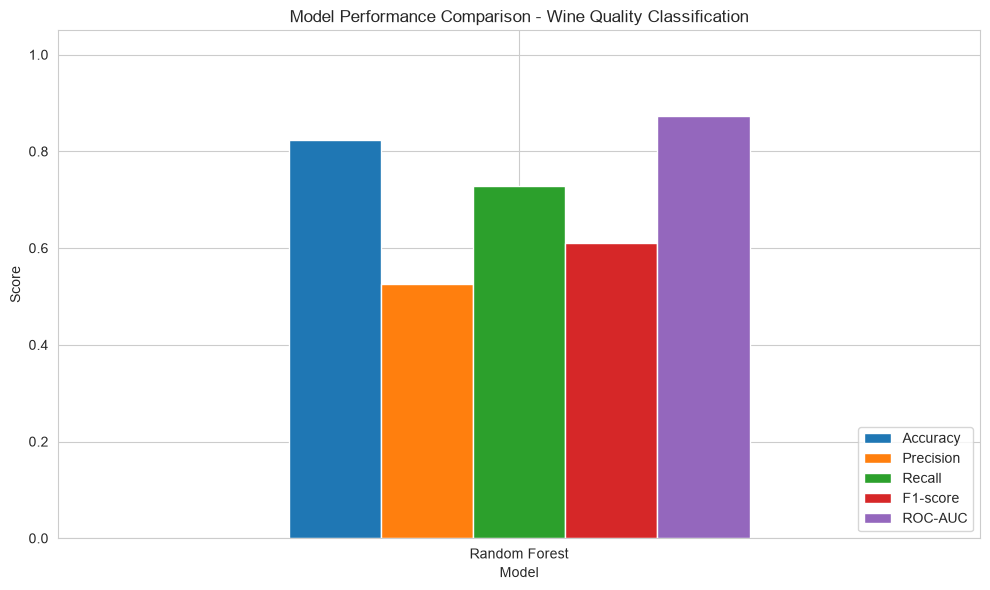

In [83]:
# Metric comparison bar chart
fig, ax = plt.subplots(figsize=(10, 6))
results_df.plot(kind="bar", ax=ax)
ax.set_title("Model Performance Comparison - Wine Quality Classification")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.legend(loc="lower right")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("metric_comparison.png", dpi=150)
plt.show()


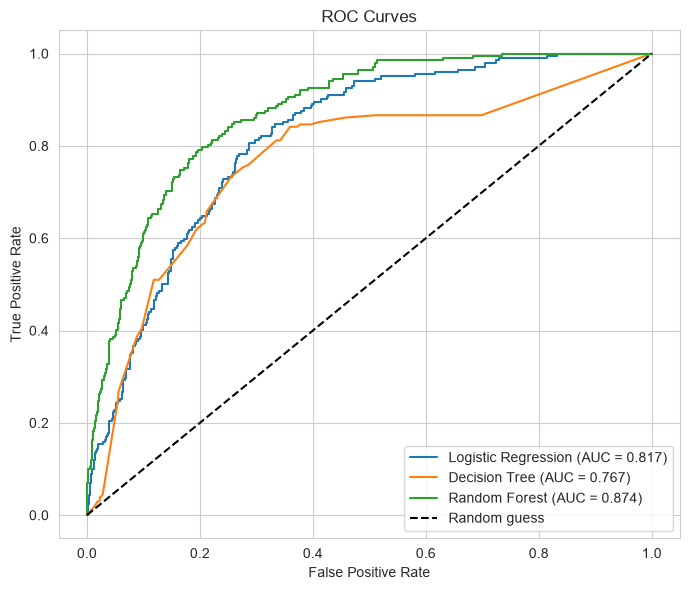

In [84]:
# ROC curves
fig, ax = plt.subplots(figsize=(7, 6))
for name, (fpr, tpr, auc) in roc_data.items():
    ax.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("roc_curves.png", dpi=150)
plt.show()

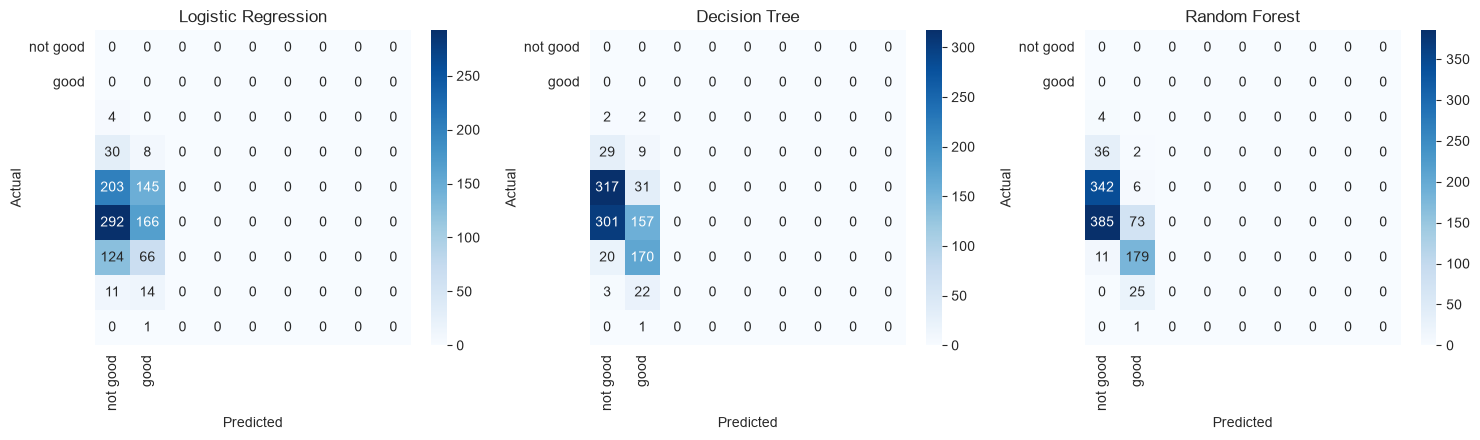

In [86]:
# Confusion matrices grid
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, model) in zip(axes, fitted.items()):
    if name == "Logistic Regression":
        y_pred = model.predict(X_test_scaled)
    else:
        # force X_test to match the exact columns the model was trained on
        X_test_aligned = X_test[model.feature_names_in_]
        y_pred = model.predict(X_test_aligned)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["not good", "good"], yticklabels=["not good", "good"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150)
plt.show()

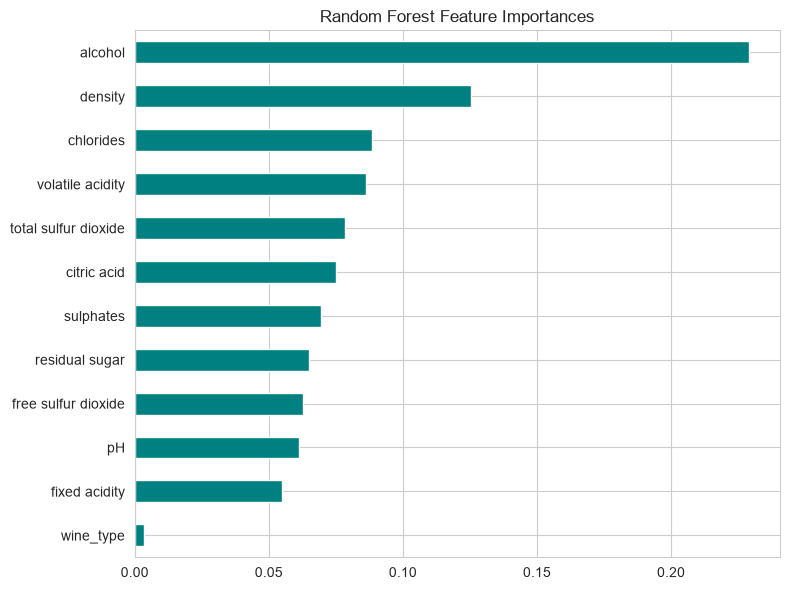

In [89]:
# Feature importance (Random Forest)
rf = fitted["Random Forest"]
importances = pd.Series(rf.feature_importances_, index=rf.feature_names_in_).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 6))
importances.plot(kind="barh", ax=ax, color="teal")
ax.invert_yaxis()
ax.set_title("Random Forest Feature Importances")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)
plt.show()

In [90]:
print("\nSaved plots: metric_comparison.png, roc_curves.png, confusion_matrices.png, feature_importance.png")
print("\nTop features by RF importance:")
print(importances.head(6))


Saved plots: metric_comparison.png, roc_curves.png, confusion_matrices.png, feature_importance.png

Top features by RF importance:
alcohol                 0.229166
density                 0.125484
chlorides               0.088547
volatile acidity        0.086352
total sulfur dioxide    0.078322
citric acid             0.075132
dtype: float64


In [75]:
print(df.head())

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.66         0.00             1.8      0.075   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 13.0                  40.0   0.9978  3.51       0.56   

   alcohol  quality  wine_type  good_quality  
0      9.4        5          0         

In [76]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 5320 entries, 0 to 5319
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         5320 non-null   float64
 1   volatile acidity      5320 non-null   float64
 2   citric acid           5320 non-null   float64
 3   residual sugar        5320 non-null   float64
 4   chlorides             5320 non-null   float64
 5   free sulfur dioxide   5320 non-null   float64
 6   total sulfur dioxide  5320 non-null   float64
 7   density               5320 non-null   float64
 8   pH                    5320 non-null   float64
 9   sulphates             5320 non-null   float64
 10  alcohol               5320 non-null   float64
 11  quality               5320 non-null   int64  
 12  wine_type             5320 non-null   int64  
 13  good_quality          5320 non-null   int64  
dtypes: float64(11), int64(3)
memory usage: 582.0 KB
None


The important things we'll look at are:

1599 entries → we have 1,599 wine records.
12 columns → we have 12 variables.
Non-Null Count → tells us whether we're missing data.
Dtype → tells us what type of data each column contains

In [77]:
print(df.isnull().sum())

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
wine_type               0
good_quality            0
dtype: int64


In [78]:
print(df["quality"].value_counts().sort_index())

quality
3      30
4     206
5    1752
6    2323
7     856
8     148
9       5
Name: count, dtype: int64


In [79]:
# Convert quality scores into classes
def classify_quality(quality):
    if quality <= 5:
        return 0
    elif quality <= 7:
        return 1
    else:
        return 2

In [80]:

df["quality_class"] = df["quality"].apply(classify_quality)

print("\nQuality classes:")
print(df["quality_class"].value_counts().sort_index())


Quality classes:
quality_class
0    1988
1    3179
2     153
Name: count, dtype: int64


In [81]:
# Separate features and target
X = df.drop("quality", axis=1)
y = df["quality"]

print("Features (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())

Features (X):
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.66         0.00             1.8      0.075   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 13.0                  40.0   0.9978  3.51       0.56   

   alcohol  wine_type  good_quality  quality_class  
0      9.4         

In [82]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4256, 14)
Testing data: (1064, 14)
